# **Práctica 1**

In [21]:
from qiskit import QuantumRegister, QuantumCircuit, generate_preset_pass_manager
from qiskit import transpile
from qiskit_aer import Aer
# from qiskit.visualization import plot_bloch_multivector, plot_histogram
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
from qiskit_aer import AerSimulator
from qiskit.circuit.library import *

import numpy as np
# Importing standard Qiskit libraries
from qiskit.visualization import *

from qiskit.quantum_info import Statevector, Pauli

from tabulate import tabulate

from functools import reduce
import matplotlib.pyplot as plt



## **Bloque 1: Funcionamiento de las puertas cuánticas de 1 qubit**

In [2]:
# Creo una lista con las puertas que voy a utilizar
gates = [XGate(), YGate(), ZGate(), HGate(), SGate(), TGate()]

sv0, sv1 = [], []

In [3]:
# Aplico las puertas al estado 0
for g in gates:
    aux0 = QuantumCircuit(1)
    aux0.append(g, aux0.qubits)
    sv0.append(Statevector(aux0))


    aux1 = QuantumCircuit(1)
    aux1.x(0) # Le aplico una puerta X para cambiar del estado |0> al |1>

    aux1.append(g, aux1.qubits)
    sv1.append(Statevector(aux1))

In [5]:
gates_names = ['X', 'Y', 'Z', 'H', 'S', 'T']
headers = ['Puertas', 'Estado |0>', 'Estado |1>']
data = [[gates_names[i], sv0[i].data, sv1[i].data] for i in range(len(gates_names))]

table = tabulate(data, headers = headers)

print(table)

Puertas    Estado |0>                       Estado |1>
---------  -------------------------------  -----------------------------------------------
X          [0.+0.j 1.+0.j]                  [1.+0.j 0.+0.j]
Y          [0.+0.j 0.+1.j]                  [0.-1.j 0.+0.j]
Z          [1.+0.j 0.+0.j]                  [ 0.+0.j -1.+0.j]
H          [0.70710678+0.j 0.70710678+0.j]  [ 0.70710678+0.j -0.70710678+0.j]
S          [1.+0.j 0.+0.j]                  [0.+0.j 0.+1.j]
T          [1.+0.j 0.+0.j]                  [0.        +0.j         0.70710678+0.70710678j]


In [ ]:
# Obtenemos el vector real de la esfera de bloch
def bloch_vector(sv):
    return [sv.expectation_value(Pauli(p)).real for p in 'XYZ']

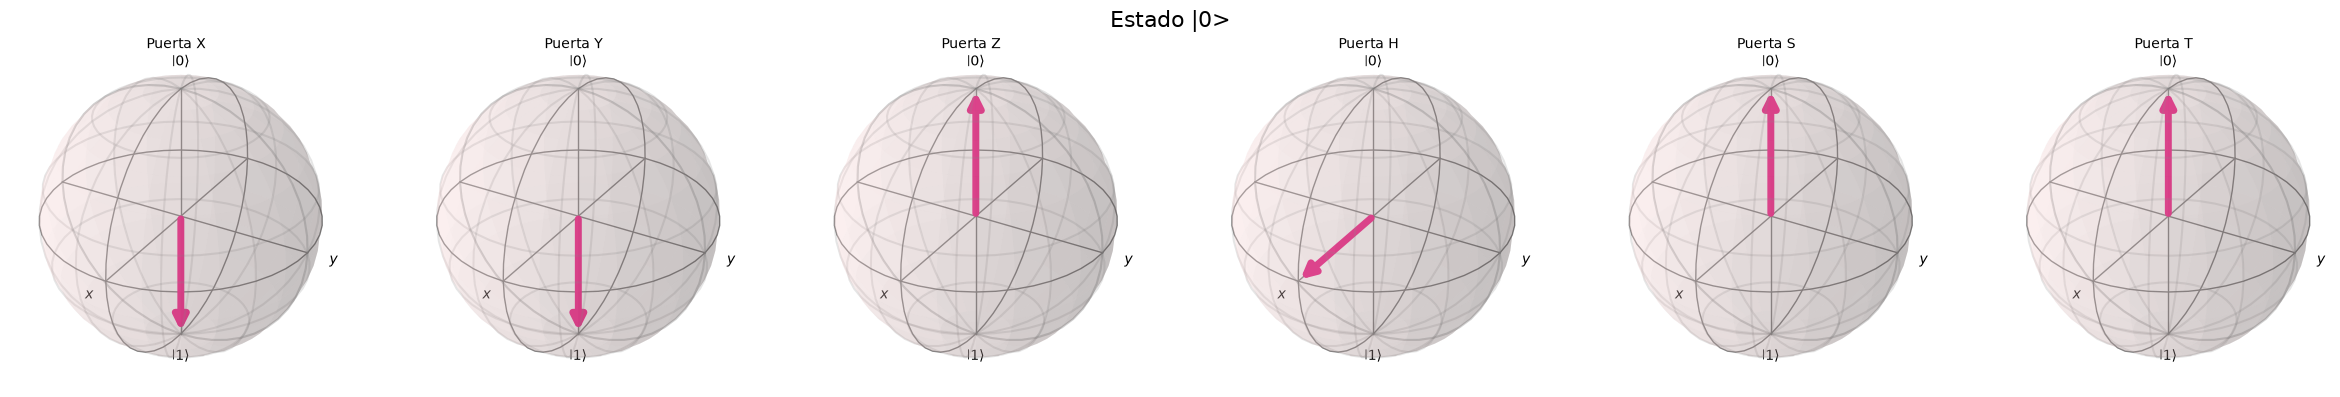

In [27]:
n = len(sv0)
ncols = n
nrows = 1

fig = plt.figure(figsize=(4 * ncols, 4 * nrows))
for i, sv in enumerate(sv0):
    ax = fig.add_subplot(nrows, ncols, i + 1, projection='3d')
    plot_bloch_vector(bloch_vector(sv), title=f"Puerta {gates_names[i]}", ax=ax)

fig.suptitle("Estado |0>", fontsize=16)
fig.savefig(f'./figures/bloch_spheres_state0.png', dpi = 300, bbox_inches = 'tight')
plt.tight_layout()
plt.show()

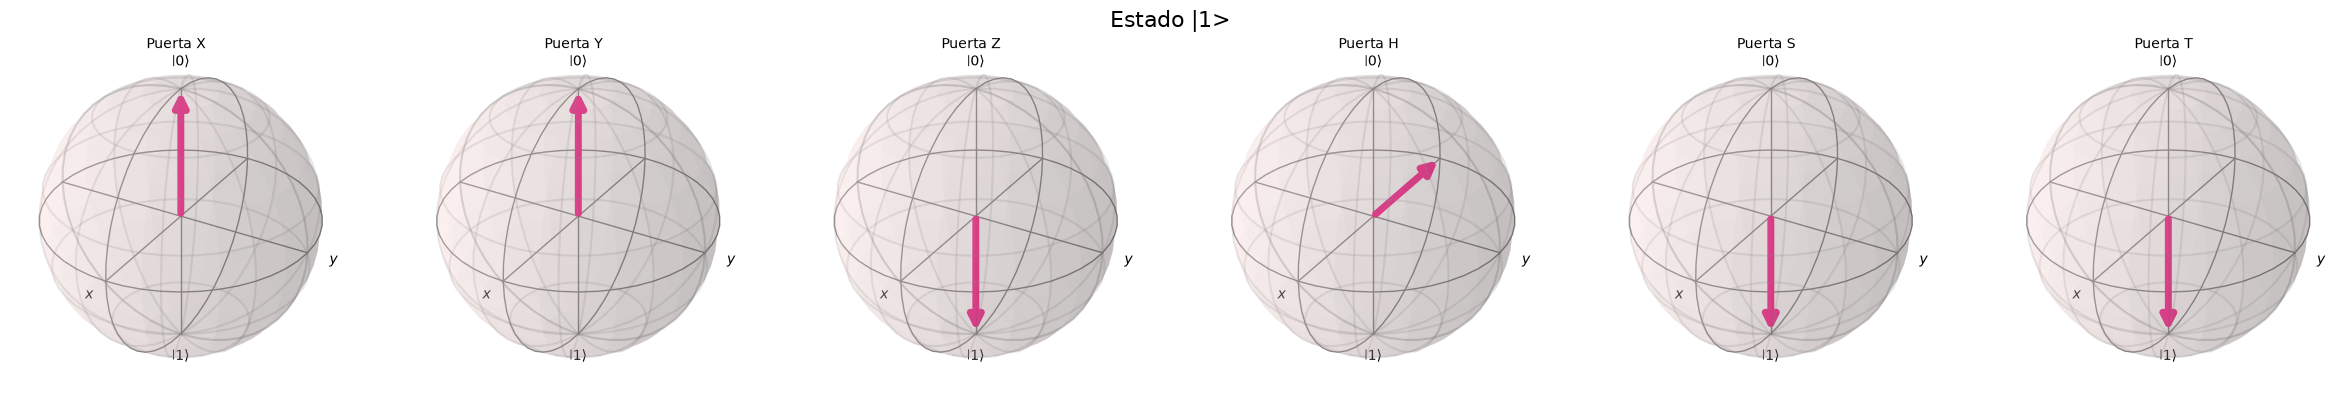

In [28]:
n = len(sv1)
ncols = n
nrows = 1

fig = plt.figure(figsize=(4 * ncols, 4 * nrows))
for i, sv in enumerate(sv1):
    ax = fig.add_subplot(nrows, ncols, i + 1, projection='3d')
    plot_bloch_vector(bloch_vector(sv), title=f"Puerta {gates_names[i]}", ax=ax)

fig.suptitle("Estado |1>", fontsize=16)
fig.savefig(f'./figures/bloch_spheres_state1.png', dpi = 300, bbox_inches = 'tight')
plt.tight_layout()
plt.show()

## **Bloque 2: Puertas de 2 qubits y equivalencias**

## **Bloque 3: Identidades de conjugación**

## **Bloque 4: Entrelazamiento - Estados de Bell**

## **Bloque 5: Operador unitario de un circuito**

## **Bloque 6: Circuitos de 3 qubits**

## **Bloque 7: Cambios de base**

## **Bloque 8: Esfera de Bloch**

## **Bloque 9: Rotaciones y evolución temporal**

## **Bloque 10: Equivalencias de circuitos**

## **Ejercicios opcionales**